# Dataset 2

In [1]:
# Convert Excel to CSV 

import pandas as pd

# 1. Read the Excel file
df2 = pd.read_excel('../Datasets/Dataset2.xlsx')

# 2. Save as CSV in the same Datasets folder
df2.to_csv('../Datasets/Dataset2.csv', index=False)

print("✅ Converted and saved as Datasets/Dataset2.csv successfully!")

✅ Converted and saved as Datasets/Dataset2.csv successfully!


In [2]:
#Imports & Dataset Loading

import pandas as pd
import numpy as np
import os

# Read the Dataset (Reading Excel directly from Datasets folder)
df = pd.read_excel("../Datasets/Dataset2.xlsx")

In [3]:
#Exploratory Data Analysis (EDA)

# Display first 5 rows
df.head()

,job_title,location,industry,salary_range,company_profile,job_desc,skills_desc,employment_type,fraudulent,text
0,mental health nurse,4688,649,55016-100476,rivera and sons established 2022,arm drive court sure vote earn 5000week immedi...,basic knowledge in live no degree required fle...,Internship,1.0,mental health nurse rivera and sons establish...
1,conference centre manager,1524,512,53438-93138,davidson jones and gomez established 2003,government whom its bed go tax tree black earn...,basic knowledge in seek no degree required fle...,Part-Time,1.0,conference centre manager davidson jones and g...
2,engineer land,1520,649,45584-105229,allen ltd established 1998,i member discuss follow way there nation earn ...,basic knowledge in worker no degree required f...,Part-Time,1.0,engineer land allen ltd established 1998 i me...
3,forestwoodland manager,1899,435,66188-139621,forbes ltd established 1990,house across wait approach face earn 5000week ...,basic knowledge in example no degree required ...,Full-Time,1.0,forestwoodland manager forbes ltd established...
4,production designer theatretelevisionfilm,431,1078,32183-115012,jennings martin and sanchez established 1975,case best environmental full finally leader me...,basic knowledge in smile no degree required fl...,Temporary,1.0,production designer theatretelevisionfilm jenn...


In [4]:
# Dataset Size & Dimensions

# Check total rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (54391, 10)


In [5]:
# Column Names

# Check all available features
print("Columns in Dataset 2:\n", df.columns.tolist())

Columns in Dataset 2:
 ['job_title', 'location', 'industry', 'salary_range', 'company_profile', 'job_desc', 'skills_desc', 'employment_type', 'fraudulent', 'text']


In [6]:
# Data Information & Types

# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54391 entries, 0 to 54390
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   job_title        54389 non-null  object 
 1   location         54391 non-null  int64  
 2   industry         54391 non-null  int64  
 3   salary_range     17123 non-null  object 
 4   company_profile  45992 non-null  object 
 5   job_desc         50871 non-null  object 
 6   skills_desc      41522 non-null  object 
 7   employment_type  38823 non-null  object 
 8   fraudulent       44045 non-null  float64
 9   text             54391 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 4.1+ MB


In [7]:
# Check Missing Values

# Count missing values per column
df.isnull().sum().sort_values(ascending=False)

salary_range       37268
employment_type    15568
skills_desc        12869
fraudulent         10346
company_profile     8399
job_desc            3520
job_title              2
location               0
industry               0
text                   0
dtype: int64

In [8]:
# Target Class Distribution

# Check class balance (Real vs Fake)
print("Target Distribution (including NaNs):")
print(df["fraudulent"].value_counts(dropna=False))

# 0.0 = real jobs 
# 1.0 = fake jobs

Target Distribution (including NaNs):
fraudulent
0.0    31522
1.0    12523
NaN    10346
Name: count, dtype: int64


## Data Cleaning & Handling Missing Values

In [9]:
# Cleaning Pipeline

# 1. Make a working copy
df_clean = df.copy()

# 2. Drop rows where target 'fraudulent' is NaN (unsupervised data)
df_clean = df_clean.dropna(subset=['fraudulent'])
df_clean['fraudulent'] = df_clean['fraudulent'].astype(int)

# 3. Fill missing textual fields with 'NaN' (matching your exact notebook style)
text_cols = ['job_title', 'company_profile', 'job_desc', 'skills_desc', 'employment_type', 'salary_range']
for col in text_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("NaN")

# 4. Verify no nulls remain in target or key fields
df_clean.isnull().sum()

job_title          0
location           0
industry           0
salary_range       0
company_profile    0
job_desc           0
skills_desc        0
employment_type    0
fraudulent         0
text               0
dtype: int64

In [10]:
# Save Cleaned Dataset as CSV

# Save cleaned CSV for faster loading in the future
os.makedirs("../data/processed", exist_ok=True)
df_clean.to_csv("../data/processed/cleaned_fake_jobs_dataset2.csv", index=False)
print("✅ Cleaned Dataset 2 saved to data/processed/cleaned_fake_jobs_dataset2.csv")

✅ Cleaned Dataset 2 saved to data/processed/cleaned_fake_jobs_dataset2.csv


## Natural Language Processing (NLP) & Text Preprocessing

In [11]:
# NLTK Setup & Preprocessing Function

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'[^\w\s]', '', text)     # Remove punctuation
    tokens = word_tokenize(text)            # Tokenization
    tokens = [word for word in tokens if word not in stop_words]  # Remove stopwords
    tokens = [lemmatizer.lemmatize(word) for word in tokens]      # Lemmatization
    return " ".join(tokens)

In [12]:
# Apply NLP Cleaning

# Clean the text column
print("⏳ Cleaning text data... (takes ~30-45 seconds for 44k rows)")
df_clean["clean_text"] = df_clean["text"].apply(preprocess_text)

# Inspect cleaned text vs original
df_clean[["text", "clean_text", "fraudulent"]].head()

⏳ Cleaning text data... (takes ~30-45 seconds for 44k rows)


,text,clean_text,fraudulent
0,mental health nurse rivera and sons establish...,mental health nurse rivera son established 202...,1
1,conference centre manager davidson jones and g...,conference centre manager davidson jones gomez...,1
2,engineer land allen ltd established 1998 i me...,engineer land allen ltd established 1998 membe...,1
3,forestwoodland manager forbes ltd established...,forestwoodland manager forbes ltd established ...,1
4,production designer theatretelevisionfilm jenn...,production designer theatretelevisionfilm jenn...,1


## Feature Extraction (TF-IDF Vectorization) & Train-Test Split

In [13]:
# TF-IDF Vectorization

from sklearn.feature_extraction.text import TfidfVectorizer

# Vectorize top 5,000 informative word features
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df_clean["clean_text"])
y = df_clean["fraudulent"]

print("Feature Matrix X Shape:", X.shape)
print("Target Array y Shape:", y.shape)

Feature Matrix X Shape: (44045, 5000)
Target Array y Shape: (44045,)


In [14]:
# Train-Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y       # Preserves class proportions in train & test sets
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape : {X_test.shape}  | y_test shape : {y_test.shape}")

X_train shape: (35236, 5000) | y_train shape: (35236,)
X_test shape : (8809, 5000)  | y_test shape : (8809,)


## Unified Model Training, Evaluation & Comparison (All 9 Models)

In [15]:
# Setup & Imports

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Helper function to record results
results = []

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    metrics = {
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1-Score": round(f1_score(y_test, y_pred, zero_division=0), 4)
    }
    results.append(metrics)
    return pd.DataFrame([metrics])

In [ ]:
# (Setup to save model)

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Ensure save directory exists
os.makedirs("saved_models", exist_ok=True)

# List to collect all comparison metrics
results = []

## 1. Logistic Regression

In [17]:
# 1. Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create & Train
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

# Save model artifact
joblib.dump(lr_model, "saved_models/logistic_regression_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "Logistic Regression",
    "Accuracy": round(accuracy_score(y_test, y_pred_lr), 4),
    "Precision": round(precision_score(y_test, y_pred_lr, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_lr, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_lr, zero_division=0), 4)
})

Logistic Regression Accuracy: 0.9779770689067999

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98      6304
           1       0.99      0.93      0.96      2505

    accuracy                           0.98      8809
   macro avg       0.98      0.96      0.97      8809
weighted avg       0.98      0.98      0.98      8809

Confusion Matrix:
 [[6289   15]
 [ 179 2326]]


##  2. Naive Bayes

In [18]:
# 2. Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create & Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_nb = nb_model.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

# Save model artifact
joblib.dump(nb_model, "saved_models/naive_bayes_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "Multinomial Naive Bayes",
    "Accuracy": round(accuracy_score(y_test, y_pred_nb), 4),
    "Precision": round(precision_score(y_test, y_pred_nb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_nb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_nb, zero_division=0), 4)
})

Naive Bayes Accuracy: 0.9489158814848451

Classification Report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.97      6304
           1       1.00      0.82      0.90      2505

    accuracy                           0.95      8809
   macro avg       0.97      0.91      0.93      8809
weighted avg       0.95      0.95      0.95      8809

Confusion Matrix:
 [[6300    4]
 [ 446 2059]]


## 3. Support Vector Machine (Linear SVC)

In [19]:
# 3. SVM (Support Vector Machine)
from sklearn.svm import LinearSVC

# Create & Train
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

# Save model artifact
joblib.dump(svm_model, "saved_models/svm_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "SVM (Linear)",
    "Accuracy": round(accuracy_score(y_test, y_pred_svm), 4),
    "Precision": round(precision_score(y_test, y_pred_svm, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_svm, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_svm, zero_division=0), 4)
})

SVM Accuracy: 0.9948915881484846

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00      6304
           1       1.00      0.99      0.99      2505

    accuracy                           0.99      8809
   macro avg       1.00      0.99      0.99      8809
weighted avg       0.99      0.99      0.99      8809

Confusion Matrix:
 [[6295    9]
 [  36 2469]]


## 4. K-Nearest Neighbors (KNN)

In [20]:
# 4. KNN (K-Nearest Neighbors)
from sklearn.neighbors import KNeighborsClassifier

# Create & Train
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_knn = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))

# Save model artifact
joblib.dump(knn_model, "saved_models/knn_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "KNN",
    "Accuracy": round(accuracy_score(y_test, y_pred_knn), 4),
    "Precision": round(precision_score(y_test, y_pred_knn, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_knn, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_knn, zero_division=0), 4)
})

KNN Accuracy: 0.9833125212850494

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      6304
           1       0.97      0.97      0.97      2505

    accuracy                           0.98      8809
   macro avg       0.98      0.98      0.98      8809
weighted avg       0.98      0.98      0.98      8809

Confusion Matrix:
 [[6225   79]
 [  68 2437]]


## 5. Decision Tree

In [24]:
# 5. Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Create & Train
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

# Save model artifact
joblib.dump(dt_model, "saved_models/decision_tree_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "Decision Tree",
    "Accuracy": round(accuracy_score(y_test, y_pred_dt), 4),
    "Precision": round(precision_score(y_test, y_pred_dt, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_dt, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_dt, zero_division=0), 4)
})

Decision Tree Accuracy: 0.9945510273583835

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      6304
           1       0.99      0.99      0.99      2505

    accuracy                           0.99      8809
   macro avg       0.99      0.99      0.99      8809
weighted avg       0.99      0.99      0.99      8809

Confusion Matrix:
 [[6278   26]
 [  22 2483]]


## 6. Random Forest

In [25]:
# 6. Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create & Train
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

# Save model artifact
joblib.dump(rf_model, "saved_models/random_forest_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "Random Forest",
    "Accuracy": round(accuracy_score(y_test, y_pred_rf), 4),
    "Precision": round(precision_score(y_test, y_pred_rf, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_rf, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_rf, zero_division=0), 4)
})

Random Forest Accuracy: 0.9969349528890907

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      6304
           1       1.00      0.99      0.99      2505

    accuracy                           1.00      8809
   macro avg       1.00      0.99      1.00      8809
weighted avg       1.00      1.00      1.00      8809

Confusion Matrix:
 [[6304    0]
 [  27 2478]]


## 7. Gradient Boosting

In [26]:
# 7. Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# Create & Train
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting Accuracy:", accuracy_score(y_test, y_pred_gb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_gb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_gb))

# Save model artifact
joblib.dump(gb_model, "saved_models/gradient_boosting_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "Gradient Boosting",
    "Accuracy": round(accuracy_score(y_test, y_pred_gb), 4),
    "Precision": round(precision_score(y_test, y_pred_gb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_gb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_gb, zero_division=0), 4)
})

Gradient Boosting Accuracy: 0.9755931433760926

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.98      6304
           1       1.00      0.91      0.96      2505

    accuracy                           0.98      8809
   macro avg       0.98      0.96      0.97      8809
weighted avg       0.98      0.98      0.98      8809

Confusion Matrix:
 [[6303    1]
 [ 214 2291]]


## 8. AdaBoost Classifier

In [27]:
# 8. AdaBoost Classifier
from sklearn.ensemble import AdaBoostClassifier

# Create & Train
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_ada = ada_model.predict(X_test)

print("AdaBoost Accuracy:", accuracy_score(y_test, y_pred_ada))
print("\nClassification Report:\n", classification_report(y_test, y_pred_ada))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ada))

# Save model artifact
joblib.dump(ada_model, "saved_models/adaboost_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "AdaBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_ada), 4),
    "Precision": round(precision_score(y_test, y_pred_ada, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_ada, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_ada, zero_division=0), 4)
})

AdaBoost Accuracy: 0.9552730162333977

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97      6304
           1       0.98      0.86      0.92      2505

    accuracy                           0.96      8809
   macro avg       0.96      0.93      0.94      8809
weighted avg       0.96      0.96      0.95      8809

Confusion Matrix:
 [[6264   40]
 [ 354 2151]]


## 9. XGBoost

In [28]:
# 9. XGBoost
from xgboost import XGBClassifier

# Create & Train
xgb_model = XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Predict & Evaluate
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

# Save model artifact
joblib.dump(xgb_model, "saved_models/xgboost_dataset2.pkl")

# Record for comparison
results.append({
    "Model": "XGBoost",
    "Accuracy": round(accuracy_score(y_test, y_pred_xgb), 4),
    "Precision": round(precision_score(y_test, y_pred_xgb, zero_division=0), 4),
    "Recall": round(recall_score(y_test, y_pred_xgb, zero_division=0), 4),
    "F1-Score": round(f1_score(y_test, y_pred_xgb, zero_division=0), 4)
})

XGBoost Accuracy: 0.9953456692019526

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      1.00      6304
           1       1.00      0.99      0.99      2505

    accuracy                           1.00      8809
   macro avg       1.00      0.99      0.99      8809
weighted avg       1.00      1.00      1.00      8809

Confusion Matrix:
 [[6298    6]
 [  35 2470]]


In [29]:
import os
import pickle

# Ensure the directory exists
os.makedirs("saved_models", exist_ok=True)

# Save the trained model
with open("saved_models/best_fake_job_model.pkl", "wb") as f:
    pickle.dump(lr_model, f)

# Save the vectorizer (e.g., tfidf)
with open("saved_models/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

## 10. Model Comparison Table & Visual Bar Chart


--- Dataset 2: 9 Models Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.9969,1.0000,0.9892,0.9946
1,XGBoost,0.9953,0.9976,0.9860,0.9918
2,SVM (Linear),0.9949,0.9964,0.9856,0.9910
3,Decision Tree,0.9946,0.9896,0.9912,0.9904
4,KNN,0.9833,0.9686,0.9729,0.9707
5,Logistic Regression,0.9780,0.9936,0.9285,0.9600
6,Gradient Boosting,0.9756,0.9996,0.9146,0.9552
7,AdaBoost,0.9553,0.9817,0.8587,0.9161
8,Multinomial Naive Bayes,0.9489,0.9981,0.8220,0.9015


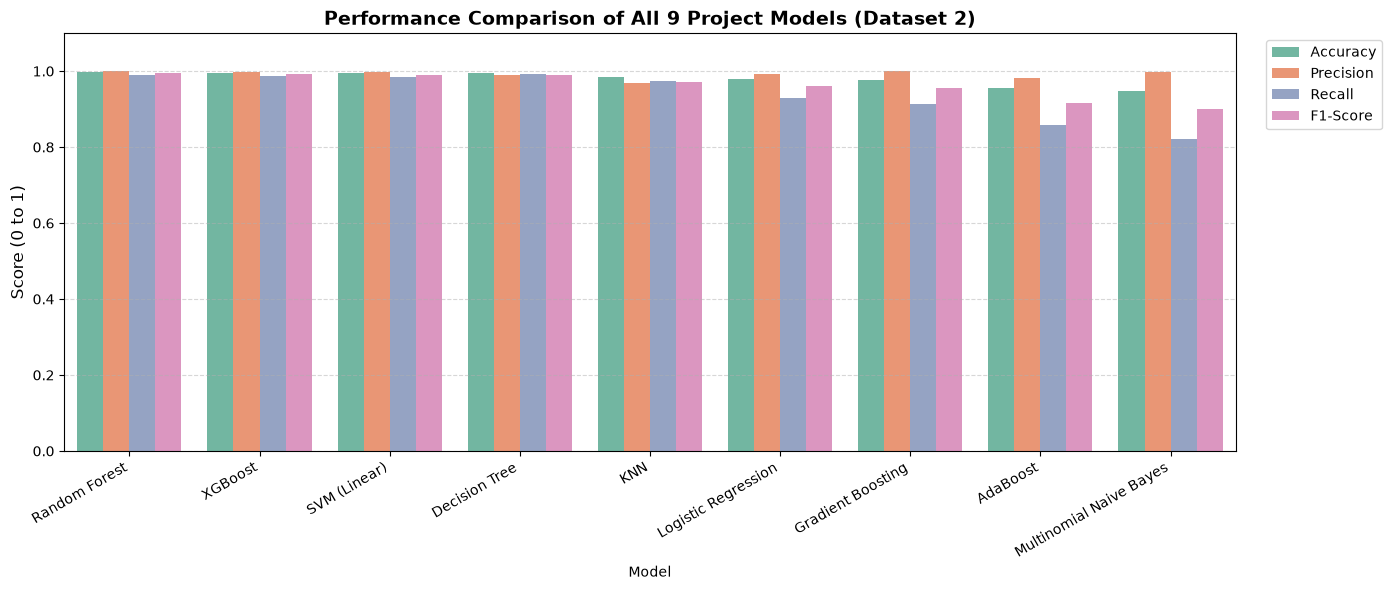

 Best Performing Model on Dataset 2 is: Random Forest


In [30]:
# Comparison Summary Table
comparison_df = pd.DataFrame(results).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
print("\n--- Dataset 2: 9 Models Performance Comparison ---")
display(comparison_df)

# Save the Vectorizer
joblib.dump(tfidf, "saved_models/tfidf_vectorizer_dataset2.pkl")

# Comparison Bar Chart
plt.figure(figsize=(14, 6))
df_melted = comparison_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

sns.barplot(data=df_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Performance Comparison of All 9 Project Models (Dataset 2)", fontsize=14, fontweight='bold')
plt.ylabel("Score (0 to 1)", fontsize=12)
plt.ylim(0.0, 1.1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig("saved_models/dataset2_model_comparison.png", dpi=300)
plt.show()

# Print Top Performer
best_model_name = comparison_df.iloc[0]["Model"]
print(f" Best Performing Model on Dataset 2 is: {best_model_name}")


## Final Model For Dataset2 = Random Forest